# Comparación de modelos supervisados

En este notebook se comparan dos algoritmos de clasificación supervisada
aplicados al dataset Wall-Following Robot Navigation:

- Random Forest.
- Support Vector Machine (SVM).

Ambos modelos utilizan exactamente los mismos conjuntos de entrenamiento
y prueba generados durante la etapa de preprocesamiento.

La comparación considera:

- Accuracy.
- F1-score ponderado.
- F1-score macro.
- Tiempo de entrenamiento.
- Matrices de confusión.

El objetivo es determinar cuál de los dos modelos ofrece el mejor
rendimiento para la clasificación de las acciones de navegación del robot.

In [13]:
from pathlib import Path
from time import perf_counter
import sys
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Obtener la raíz del proyecto.
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Permitir importar módulos desde src/.
src_path = project_root / "src"

if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

from train_supervised import (
    SENSOR_COLUMNS,
    train_random_forest,
    train_svm,
    evaluate_model
)

print("Raíz del proyecto:")
print(project_root)

Raíz del proyecto:
/mnt/DiscoD/U/MachineLearning/ml-practica1-zurita


## Carga de los datos procesados

Se utiliza `dataset.parquet`, generado durante la etapa de preprocesamiento.

La columna `split` permite recuperar exactamente los mismos conjuntos
de entrenamiento y prueba utilizados en los experimentos anteriores.

In [14]:
dataset_path = (
    project_root
    / "data"
    / "processed"
    / "dataset.parquet"
)

df = pd.read_parquet(dataset_path)

train_df = df[df["split"] == "train"].copy()
test_df = df[df["split"] == "test"].copy()

X_train = train_df[SENSOR_COLUMNS]
y_train = train_df["Class"]

X_test = test_df[SENSOR_COLUMNS]
y_test = test_df["Class"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (4364, 24)
y_train: (4364,)

X_test: (1092, 24)
y_test: (1092,)


## Entrenamiento y evaluación

Los dos modelos se entrenan utilizando exactamente `X_train` y `y_train`.

Posteriormente se evalúan sobre el mismo conjunto `X_test` y `y_test`,
lo que permite realizar una comparación directa de sus resultados.

In [15]:
# Random Forest
rf_start = perf_counter()

random_forest = train_random_forest(
    X_train,
    y_train
)

rf_time = perf_counter() - rf_start

rf_metrics = evaluate_model(
    random_forest,
    X_test,
    y_test
)


# SVM
svm_start = perf_counter()

svm_model = train_svm(
    X_train,
    y_train
)

svm_time = perf_counter() - svm_start

svm_metrics = evaluate_model(
    svm_model,
    X_test,
    y_test
)

print("Entrenamiento completado.")

Entrenamiento completado.


In [16]:
comparison = pd.DataFrame(
    {
        "Modelo": [
            "Random Forest",
            "SVM"
        ],
        "Accuracy": [
            rf_metrics["accuracy"],
            svm_metrics["accuracy"]
        ],
        "F1 ponderado": [
            rf_metrics["f1_weighted"],
            svm_metrics["f1_weighted"]
        ],
        "F1 macro": [
            rf_metrics["f1_macro"],
            svm_metrics["f1_macro"]
        ],
        "Tiempo (s)": [
            rf_time,
            svm_time
        ]
    }
)

comparison.round(4)

,Modelo,Accuracy,F1 ponderado,F1 macro,Tiempo (s)
0,Random Forest,0.9927,0.9927,0.9894,0.9854
1,SVM,0.8690,0.8684,0.8692,0.5712


## Interpretación inicial

Random Forest presenta un rendimiento considerablemente superior a SVM
en las métricas de clasificación.

Random Forest alcanza aproximadamente un 99 % de accuracy y F1-score,
mientras que SVM obtiene valores cercanos al 87 %.

Aunque SVM presenta un menor tiempo de entrenamiento en esta ejecución,
la diferencia temporal es pequeña frente a la pérdida observada en la
capacidad de clasificación.

El F1-score macro también favorece ampliamente a Random Forest, lo que
indica que su buen rendimiento se mantiene al considerar todas las clases
con la misma importancia, incluyendo las clases minoritarias.

## Comparación gráfica de las métricas

Se comparan visualmente Accuracy, F1-score ponderado y F1-score macro
para determinar qué modelo presenta el mejor rendimiento de clasificación.

Las métricas se muestran en la misma escala, entre 0 y 1, lo que permite
una comparación directa entre ambos modelos.

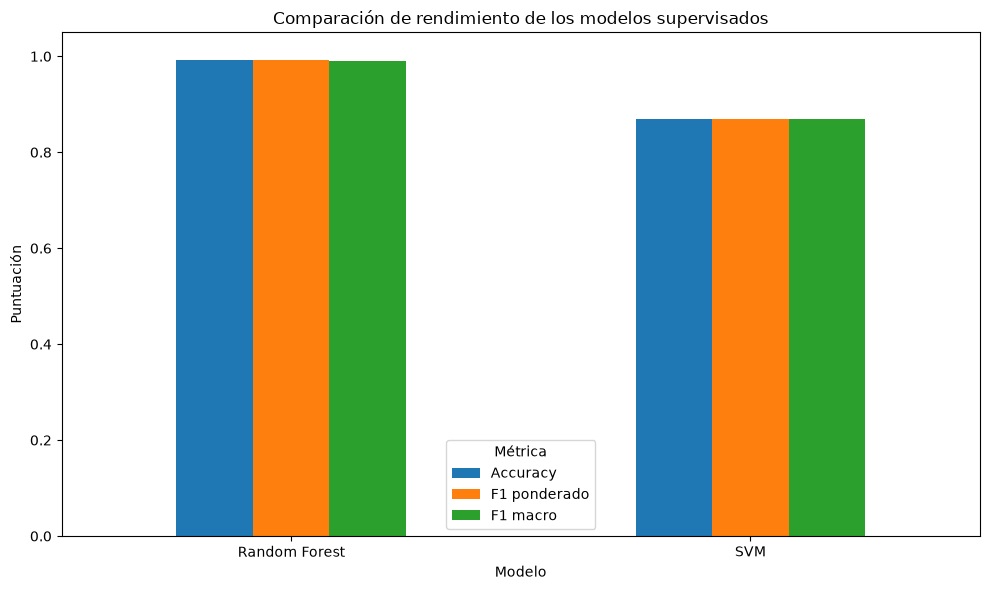

In [17]:
metrics_to_plot = comparison.set_index("Modelo")[
    [
        "Accuracy",
        "F1 ponderado",
        "F1 macro"
    ]
]

ax = metrics_to_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparación de rendimiento de los modelos supervisados")
plt.xlabel("Modelo")
plt.ylabel("Puntuación")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title="Métrica")
plt.tight_layout()
plt.show()

### Interpretación del rendimiento

Random Forest supera a SVM en las tres métricas de clasificación.

El modelo Random Forest alcanza aproximadamente 99.27 % de accuracy,
mientras que SVM alcanza aproximadamente 86.90 %.

La diferencia también se mantiene en el F1-score ponderado y el F1-score
macro. Esto indica que la superioridad de Random Forest no se limita al
rendimiento global, sino que también mantiene un comportamiento más
consistente entre las diferentes clases.

El F1-score macro resulta especialmente importante debido al desbalance
existente en el dataset. Random Forest obtiene aproximadamente 98.94 %,
frente a 86.92 % de SVM.

## Comparación del tiempo de entrenamiento

El tiempo de entrenamiento permite comparar el costo computacional inicial
de ambos modelos.

Esta medición puede variar entre ejecuciones debido a la carga del sistema,
por lo que debe interpretarse como una referencia experimental y no como
un valor absoluto del algoritmo.

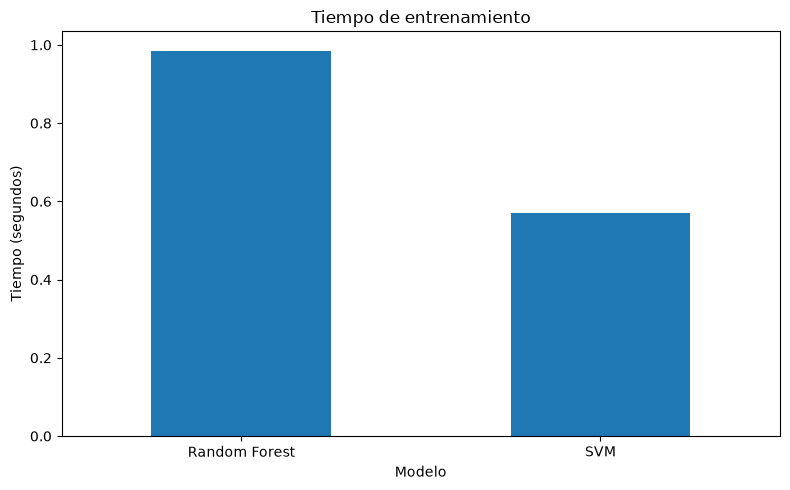

In [18]:
time_comparison = comparison.set_index("Modelo")[
    "Tiempo (s)"
]

ax = time_comparison.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Tiempo de entrenamiento")
plt.xlabel("Modelo")
plt.ylabel("Tiempo (segundos)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interpretación del tiempo de entrenamiento

En esta ejecución, SVM presentó un menor tiempo de entrenamiento que
Random Forest.

SVM tardó aproximadamente 0.58 segundos, mientras que Random Forest
requirió aproximadamente 0.94 segundos.

Sin embargo, ambos tiempos son inferiores a un segundo y la reducción
obtenida con SVM está acompañada de una disminución considerable en las
métricas de clasificación.

Por esta razón, para este problema el menor tiempo de entrenamiento de
SVM no compensa la pérdida observada en Accuracy y F1-score.

## Matrices de confusión

Las matrices de confusión permiten analizar en qué clases se producen
los errores de cada modelo.

Los valores de la diagonal principal representan clasificaciones correctas,
mientras que los valores fuera de la diagonal representan errores.

In [19]:
def plot_confusion_matrix(confusion_df, title):
    """
    Muestra una matriz de confusión con etiquetas simplificadas
    para mejorar su legibilidad.
    """

    cm = confusion_df.copy()

    # Eliminar prefijos largos de las etiquetas.
    cm.index = [
        label.replace("Real: ", "")
        for label in cm.index
    ]

    cm.columns = [
        label.replace("Pred: ", "")
        for label in cm.columns
    ]

    plt.figure(figsize=(9, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cbar=False
    )

    plt.title(title)
    plt.xlabel("Clase predicha")
    plt.ylabel("Clase real")

    plt.xticks(
        rotation=25,
        ha="right"
    )

    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

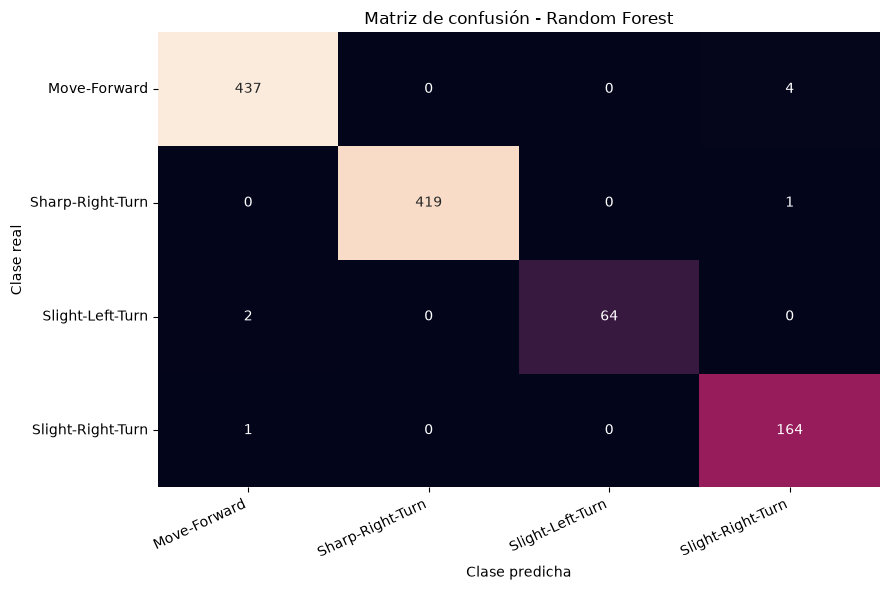

In [20]:
plot_confusion_matrix(
    rf_metrics["confusion_matrix"],
    "Matriz de confusión - Random Forest"
)

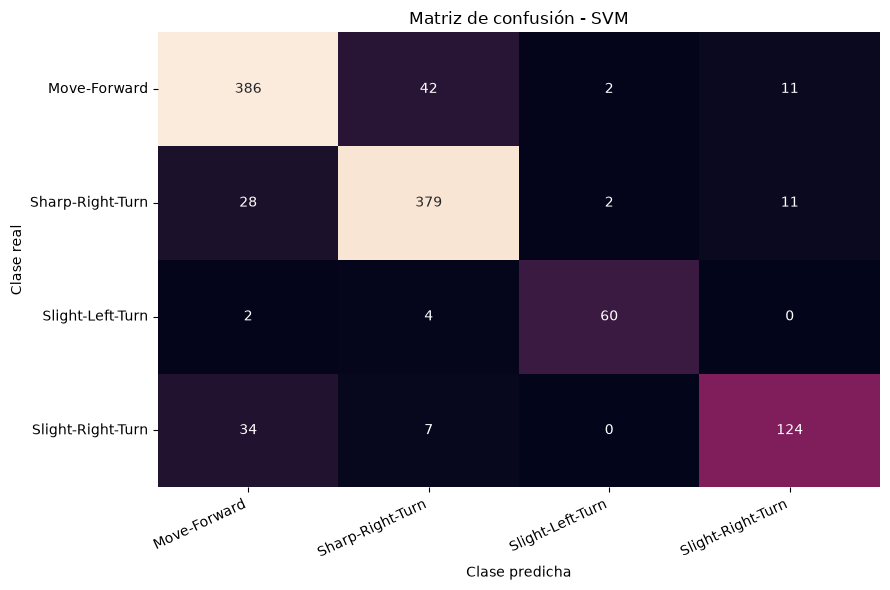

In [21]:
plot_confusion_matrix(
    svm_metrics["confusion_matrix"],
    "Matriz de confusión - SVM"
)

### Análisis de las matrices de confusión

Random Forest presenta una concentración casi completa de observaciones
en la diagonal principal de su matriz de confusión.

De las 1092 observaciones de prueba, Random Forest clasificó correctamente
1084 y cometió únicamente 8 errores.

SVM clasificó correctamente 949 observaciones y cometió 143 errores.

En SVM se observa una mayor confusión entre varias acciones de navegación.
La clase `Slight-Right-Turn` presenta una dificultad especialmente notable,
con 124 clasificaciones correctas de 165 observaciones reales.

Random Forest, en cambio, mantiene un rendimiento elevado incluso para
las clases menos representadas del dataset.

## Conclusión

Los resultados obtenidos muestran que Random Forest es el modelo
supervisado con mejor rendimiento para el dataset analizado.

Random Forest alcanzó aproximadamente 99.27 % de Accuracy, 99.27 % de
F1-score ponderado y 98.94 % de F1-score macro.

SVM obtuvo aproximadamente 86.90 % de Accuracy, 86.84 % de F1-score
ponderado y 86.92 % de F1-score macro.

Aunque SVM presentó un menor tiempo de entrenamiento en esta ejecución,
la diferencia temporal es pequeña frente a la reducción observada en
el rendimiento predictivo.

Las matrices de confusión también muestran una diferencia importante:
Random Forest cometió únicamente 8 errores sobre 1092 observaciones de
prueba, mientras que SVM cometió 143.

Por lo tanto, considerando conjuntamente Accuracy, F1-score, comportamiento
entre clases y errores de clasificación, Random Forest constituye la mejor
alternativa entre los dos modelos evaluados.

Estos resultados corresponden a los modelos utilizados sin un proceso de
optimización exhaustiva de hiperparámetros, por lo que representan una
comparación inicial bajo las condiciones establecidas en la práctica.